# Statystyka a uczenie maszynowe

Statystyka i uczenie maszynowe wyrosły z różnych tradycji, ale dziś są ściśle powiązane i wzajemnie się uzupełniają. Często używają tych samych algorytmów (np. regresji liniowej), lecz mają **inne cele**.

**Plan notatnika:**
1. Historyczne korzenie obu dziedzin
2. Główne różnice w celach i podejściu
3. Przykład: regresja liniowa w dwóch światach (dane, statystyka, uczenie maszynowe)
4. Podsumowanie

## 1. Historyczne korzenie obu dziedzin

| Statystyka | Uczenie maszynowe |
| :--- | :--- |
| Starożytność: spisy ludności, rejestry podatkowe | Lata 50.: pierwsze próby stworzenia „myślących maszyn” (Turing) |
| XVII–XVIII w.: teoria prawdopodobieństwa (Pascal, Fermat, Bernoulli) | Lata 60.: pierwsze algorytmy uczenia się (perceptron Rosenblatta) |
| XIX w.: nowoczesna statystyka (Gauss, Laplace, Pearson) | Lata 80.: odrodzenie zainteresowania sieciami neuronowymi |
| XX w.: wnioskowanie statystyczne (Fisher, Neyman, Pearson) | Lata 90. i 2000.: SVM, boosting, lasy losowe |
| | XXI w.: era Big Data i deep learningu |

**Punkty wspólne:**
- wspólne fundamenty matematyczne (rachunek prawdopodobieństwa, algebra liniowa),
- podobne techniki (regresja, klasyfikacja).

## 2. Główne różnice w celach i podejściu

| Cecha | Statystyka | Uczenie maszynowe |
| :--- | :--- | :--- |
| **Główny cel** | **Wnioskowanie (inference)** | **Predykcja (prediction)** |
| **Pytanie** | Jakie są relacje między zmiennymi? Czy są istotne statystycznie? | Jak dobrze model przewiduje wyniki dla nowych danych? |
| **Model** | Zwykle prosty, interpretowalny, oparty na założeniach (np. rozkład normalny) | Często bardziej złożony („czarna skrzynka”), elastyczny, mniej założeń |
| **Ocena** | Testy istotności (p-value), R², AIC, BIC | Dokładność, precyzja, MSE, F1 na zbiorze testowym |
| **Dane** | Mniejsze, starannie zebrane zbiory | Duże zbiory danych |
| **Nazewnictwo** | Zmienne, współczynniki, dopasowanie | Cechy (*features*), wagi, uczenie (*learning*) |
| **Przykład** | „Czy wydatki na reklamę (X) mają istotny wpływ na sprzedaż (Y)?” | „Jaka będzie sprzedaż (Y), jeśli wydamy na reklamę X złotych?” |

## 3. Przykład: regresja liniowa w dwóch światach

**Problem:** chcemy zrozumieć i przewidzieć cenę mieszkania na podstawie jego powierzchni.

Użyjemy syntetycznych danych: cena = 250 000 + 5000 zł za każdy m² + losowy szum (o odchyleniu standardowym 50 000 zł). Znamy więc „prawdę”, którą modele powinny odtworzyć.

**Uwaga:** w obu podejściach użyjemy tego samego prostego modelu (regresja liniowa). Różni się **cel** i **sposób oceny**.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

rng = np.random.default_rng(42)

powierzchnia = rng.uniform(30, 130, size=100)                          # od 30 do 130 m²
cena = 250_000 + 5000 * powierzchnia + rng.normal(0, 50_000, size=100)  # + losowy szum

data = pd.DataFrame({'powierzchnia': powierzchnia.round(1), 'cena': cena.round(0)})
data.head()

Bad value in file PosixPath('/Users/tomasz/.matplotlib/stylelib/company.mplstyle'), line 3 ("axes.prop_cycle: cycler('color', ['#123D98', '#C21E3C', '#E2A713', '#00AEEF', '#7F3F98'])"): Key axes.prop_cycle: "cycler('color', ['" is not a valid cycler construction: Could not parse "cycler('color', ['": unterminated string literal (detected at line 1) (<unknown>, line 1)
Bad value in file PosixPath('/Users/tomasz/.matplotlib/stylelib/company.mplstyle'), line 6 ('grid.color: #e0e0e0'): Key grid.color: '' does not look like a color arg


,powierzchnia,cena
0,107.4,806967.0
1,73.9,574165.0
2,115.9,810391.0
3,99.7,813645.0
4,39.4,429275.0


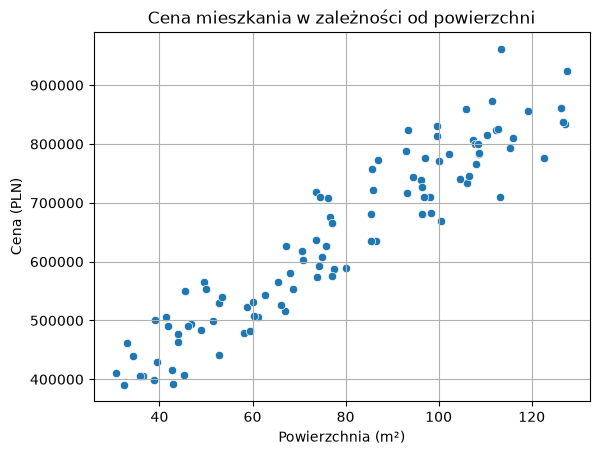

In [2]:
sns.scatterplot(data=data, x='powierzchnia', y='cena')
plt.title('Cena mieszkania w zależności od powierzchni')
plt.xlabel('Powierzchnia (m²)')
plt.ylabel('Cena (PLN)')
plt.grid(True)
plt.show()

### Podejście 1: statystyka (wnioskowanie)

Użyjemy biblioteki `statsmodels`, stworzonej do analizy statystycznej. Naszym celem jest **zrozumienie relacji** między zmiennymi.

**Pytania:**
1. Czy powierzchnia ma **istotny statystycznie** wpływ na cenę?
2. Jak dobrze model **wyjaśnia zmienność** w danych?
3. O ile średnio rośnie cena z każdym dodatkowym m²?

Trzy liczby, które czytamy z wyniku:
- **`coef`** – o ile zmienia się cena, gdy powierzchnia rośnie o 1 m² (oraz wyraz wolny `const`).
- **`P>|t|` (p-value)** – czy wpływ mógł wyjść przypadkiem; wartość **poniżej 0,05** oznacza wpływ istotny statystycznie.
- **`R-squared` (R²)** – jaka część zmienności ceny jest wyjaśniona przez model (od 0 do 1).
Kolumna `[0.025; 0.975]` to **przedział ufności**: zakres, w którym z 95% pewnością leży prawdziwy współczynnik.

In [3]:
import statsmodels.api as sm

X_sm = sm.add_constant(data['powierzchnia'])   # dodajemy stałą (wyraz wolny)
y_sm = data['cena']

model_stat = sm.OLS(y_sm, X_sm).fit()
print(model_stat.summary().tables[1])   # tabela współczynników
print(f"R-squared: {model_stat.rsquared:.3f}")

                   coef    std err          t      P>|t|      [0.025      0.975]
--------------------------------------------------------------------------------
const         2.463e+05   1.51e+04     16.290      0.000    2.16e+05    2.76e+05
powierzchnia  5038.2684    181.599     27.744      0.000    4677.891    5398.646
R-squared: 0.887


**Interpretacja wyników statystycznych:**
- **`const`:** ok. 246 tys. – wyraz wolny, teoretyczna cena mieszkania o powierzchni 0 m².
- **`powierzchnia`:** ok. 5038 – każdy dodatkowy m² zwiększa cenę średnio o ok. 5000 PLN. Przedział ufności (ok. 4680–5400) obejmuje wartość użytą do wygenerowania danych (5000).
- **`P>|t|` dla powierzchni:** `0.000` – wpływ powierzchni na cenę jest **istotny statystycznie**.
- **`R-squared`:** ok. `0.89` – model wyjaśnia ok. 89% zmienności ceny.

Model dopasowaliśmy do **wszystkich** danych – nie interesowała nas jakość predykcji na nowych obserwacjach.

### Podejście 2: uczenie maszynowe (predykcja)

Użyjemy biblioteki `scikit-learn`. Naszym celem jest model, który jak najlepiej **przewiduje** ceny nowych mieszkań.

**Pytania:**
1. Jak dobrze model generalizuje wiedzę na **nowych danych**, których nie widział podczas uczenia?
2. Jaki jest **typowy błąd predykcji**? (patrzymy na RMSE – pierwiastek błędu średniokwadratowego)

Dlatego dane dzielimy na zbiór **treningowy** (80%, na nim model się uczy) i **testowy** (20%, dane, których model nie widział). Jakość oceniamy na zbiorze testowym. Szczegóły podziału danych – w notebooku `06_podstawowe_koncepcje`.

In [4]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import root_mean_squared_error, r2_score

X = data[['powierzchnia']]   # cechy w scikit-learn muszą być w 2D
y = data['cena']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

model_ml = LinearRegression()
model_ml.fit(X_train, y_train)

y_pred = model_ml.predict(X_test)

print(f"Współczynnik (waga): {model_ml.coef_[0]:.2f}")
print(f"Wyraz wolny: {model_ml.intercept_:.2f}")
print(f"RMSE na zbiorze testowym: {root_mean_squared_error(y_test, y_pred):.2f} PLN")
print(f"R² na zbiorze testowym: {r2_score(y_test, y_pred):.3f}")

Współczynnik (waga): 5123.61
Wyraz wolny: 243713.01
RMSE na zbiorze testowym: 46325.77 PLN
R² na zbiorze testowym: 0.896


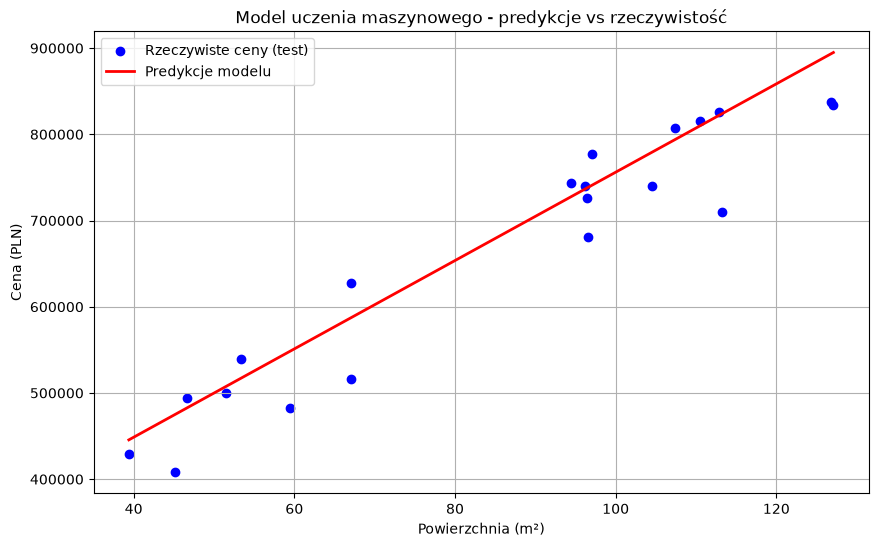

In [5]:
plt.figure(figsize=(10, 6))
plt.scatter(X_test, y_test, color='blue', label='Rzeczywiste ceny (test)')
plt.plot(X_test.sort_values('powierzchnia'),
         model_ml.predict(X_test.sort_values('powierzchnia')),
         color='red', linewidth=2, label='Predykcje modelu')
plt.title('Model uczenia maszynowego - predykcje vs rzeczywistość')
plt.xlabel('Powierzchnia (m²)')
plt.ylabel('Cena (PLN)')
plt.legend()
plt.grid(True)
plt.show()

**Interpretacja wyników ML:**
- **Współczynniki** są zbliżone do tych z modelu statystycznego – to ten sam algorytm, tylko uczony na 80% danych.
- **RMSE:** ok. 46 tys. PLN. To typowy błąd, jakiego możemy się spodziewać, przewidując cenę **nowego** mieszkania. **To nasza główna miara jakości modelu**, a nie p-value.
- **RMSE jest bliskie szumowi, który sami dodaliśmy do danych (50 tys. PLN).** Żaden model nie zejdzie poniżej szumu – to tzw. błąd nieusuwalny.
- Zbiór testowy ma tylko 20 obserwacji, więc ocena jest przybliżona; przy innym podziale wynik trochę się zmieni.

Gotowy model możemy od razu użyć do przewidywania dla nowych mieszkań:

In [6]:
nowe_mieszkanie = pd.DataFrame({'powierzchnia': [75.0]})
print(f"Przewidywana cena mieszkania 75 m²: {model_ml.predict(nowe_mieszkanie)[0]:,.0f} PLN")

Przewidywana cena mieszkania 75 m²: 627,984 PLN


## 4. Podsumowanie

- Ten sam algorytm (regresja liniowa), ale **inne pytania** i inna ocena:
  - statystyka: *czy* i *jak bardzo* powierzchnia wpływa na cenę (współczynniki, p-value, przedziały ufności),
  - uczenie maszynowe: *jak dobrze* przewidzimy cenę nowego mieszkania (błąd na zbiorze testowym).
- W praktyce data science korzysta z obu podejść: statystyka pomaga rozumieć dane, uczenie maszynowe – budować modele predykcyjne.